# Gaussian Mixtures

In [97]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs

In [98]:
# Function to plot the Gaussian components (ellipses)
def plot_gaussian_ellipses(gmm, ax):
    for i in range(gmm.n_components):
        mean = gmm.means_[i]
        cov = gmm.covariances_[i]

        # Find the principal axes using eigen-decomposition
        eigenvalues, eigenvectors = np.linalg.eigh(cov)

        # Sort from largest to smallest eigenvalue
        order = eigenvalues.argsort()[::-1]
        eigenvalues = eigenvalues[order]
        eigenvectors = eigenvectors[:, order]

        # Angle of the ellipse
        angle = np.degrees(
            np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
        )

        # Width and height of ellipse
        width, height = 2 * np.sqrt(eigenvalues)

        # Create ellipse
        ellipse = Ellipse(
            xy=mean,
            width=width,
            height=height,
            angle=angle,
            edgecolor='red',
            facecolor='none',
            linestyle='--'
        )

        ax.add_patch(ellipse)

In [99]:
# Plot Clusters

def plot_true_clusters(
    X, y,
    title="Initial Data with True Cluster Labels",
    s=10, cmap="viridis",
    figsize=(8, 6),
    ax=None, save_path=None, show=True
):
    """
    Plot the first two features of X colored by y.

    X: array-like, shape (n_samples, n_features)
    y: array-like labels (or None)
    """
    X = np.asarray(X)
    y = None if y is None else np.asarray(y)

    if X.ndim != 2 or X.shape[1] < 2:
        raise ValueError("X must be (n_samples, n_features>=2).")

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    sc = ax.scatter(X[:, 0], X[:, 1], c=y, s=s, cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

    if y is not None:
        cbar = plt.colorbar(sc, ax=ax, shrink=0.9)
        cbar.set_label("True label")

    if save_path:
        plt.savefig(save_path, bbox_inches="tight", dpi=150)

    if show:
        plt.show()

    return ax


In [100]:
X1, y1 = make_blobs(n_samples=1000,
                    centers=((4, -4), (0, 0)),
                    random_state=42
                    )


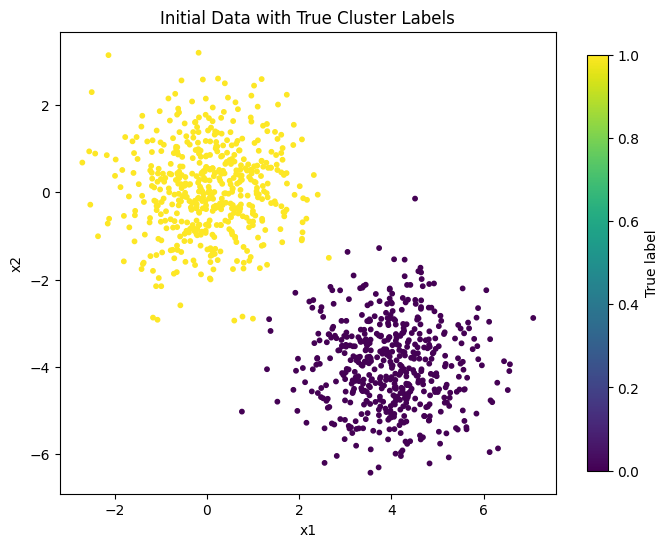

<Axes: title={'center': 'Initial Data with True Cluster Labels'}, xlabel='x1', ylabel='x2'>

In [101]:
plot_true_clusters(X1, y1)

In [102]:
X1, y1 = make_blobs(n_samples=1000,
                    centers=((4, -4), (0, 0)),
                    random_state=42
                    )
X1 = X1.dot(np.array([[0.374, 0.95], [0.732, 0.598]]))

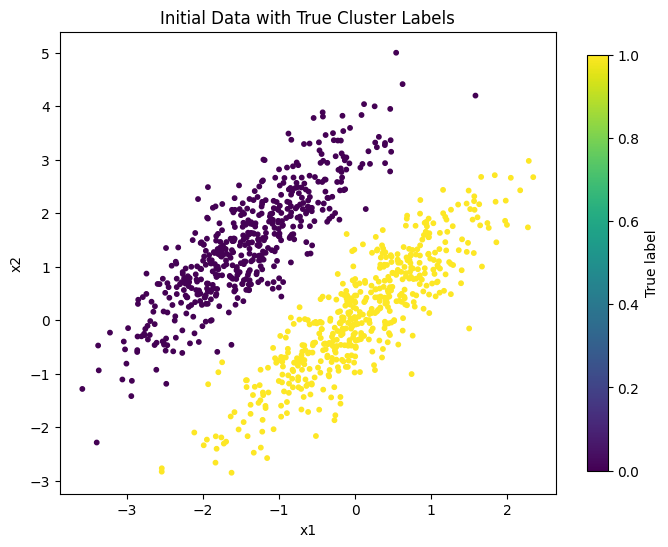

<Axes: title={'center': 'Initial Data with True Cluster Labels'}, xlabel='x1', ylabel='x2'>

In [103]:
plot_true_clusters(X1, y1)

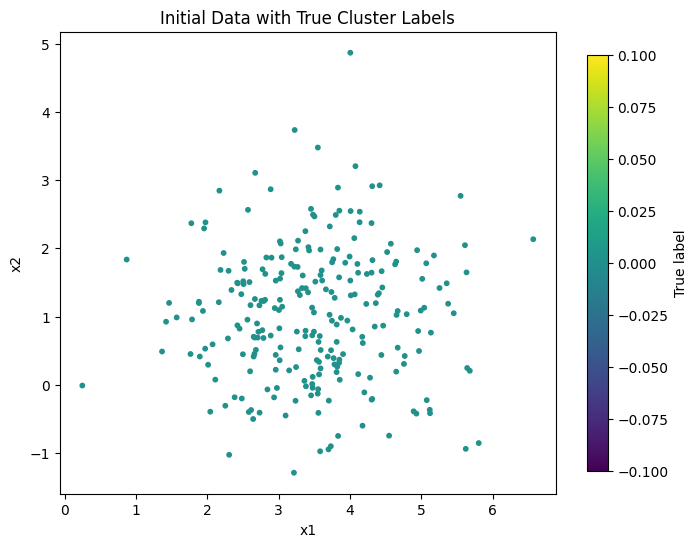

<Axes: title={'center': 'Initial Data with True Cluster Labels'}, xlabel='x1', ylabel='x2'>

In [104]:
# Generate data samples
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2 = X2 + [6, -8]
plot_true_clusters(X2, y2)

In [105]:
# Generate data samples
X1, y1 = make_blobs(n_samples=1000, centers=((4, -4), (0, 0)), random_state=42)
X1 = X1.dot(np.array([[0.374, 0.95], [0.732, 0.598]]))
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2 = X2 + [6, -8]
X = np.r_[X1, X2]
y = np.r_[y1, y2]

In [106]:
X.shape, y.shape, X[0]

((1250, 2), (1250,), array([0.81672911, 1.32719052]))

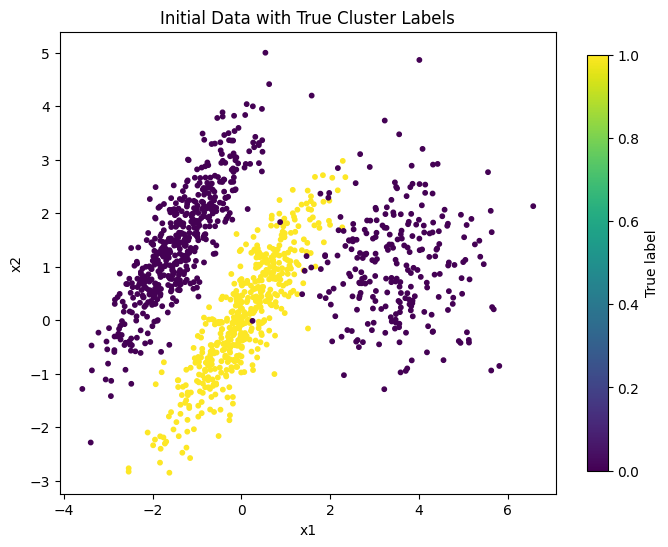

<Axes: title={'center': 'Initial Data with True Cluster Labels'}, xlabel='x1', ylabel='x2'>

In [107]:
plot_true_clusters(X, y)

## Bayesian Gaussian Mixture Models (BGMM)

In [108]:
from sklearn.mixture import BayesianGaussianMixture

In [109]:
bgm = BayesianGaussianMixture(n_components=10,
                              random_state=42)
bgm.fit(X)

/usr/local/lib/python3.13/dist-packages/sklearn/mixture/_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


BayesianGaussianMixture(n_components=10, random_state=42)

In [110]:
print(bgm.weights_.round(3))

[0.395 0.205 0.001 0.399 0.    0.    0.    0.    0.    0.   ]


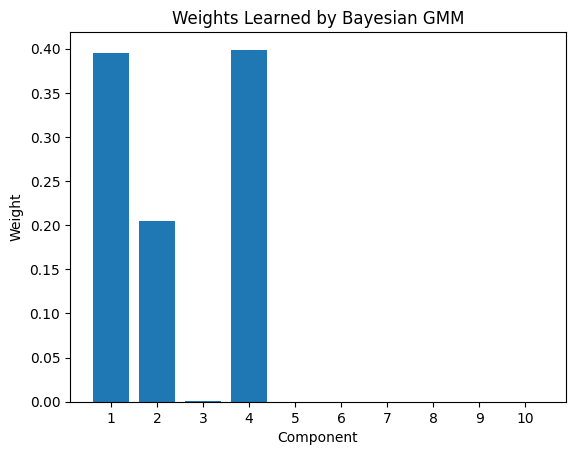

In [111]:
plt.bar(
    range(1, len(bgm.weights_) + 1),
    bgm.weights_
)

plt.xlabel('Component')
plt.ylabel('Weight')
plt.title('Weights Learned by Bayesian GMM')
plt.xticks(range(1, len(bgm.weights_) + 1))
plt.show()

## Clustering

In [112]:
# Build the GMM model with Number of Gaussian components = 3
gm = GaussianMixture(n_components=3,
                     max_iter=5,
                    #  covariance_type='full',
                     random_state=42)
gm.fit(X)

GaussianMixture(max_iter=5, n_components=3, random_state=42)

In [113]:
# Print weights, means, and covariances
print("Weights:", gm.weights_)
print("Means:", gm.means_)
print("Covariances:", gm.covariances_)

# Check if the model is converged
print("Converged?", gm.converged_)

# Print the number of iterations
print("Number of Iterations:", gm.n_iter_)

Weights: [0.39019634 0.2097235  0.40008016]
Means: [[ 0.05116693  0.07505701]
 [ 3.39839223  1.05935389]
 [-1.40763382  1.42705028]]
Covariances: [[[ 0.68778225  0.79591107]
  [ 0.79591107  1.2122181 ]]

 [[ 1.14929846 -0.03260641]
  [-0.03260641  0.95490238]]

 [[ 0.63478593  0.7296996 ]
  [ 0.7296996   1.1610729 ]]]
Converged? True
Number of Iterations: 4


In [114]:
# Predict the labels for X
labels = gm.predict(X)
labels

array([0, 0, 2, ..., 1, 1, 1])

Text(0.5, 1.0, 'GMM Clusters with Gaussian Distributions')

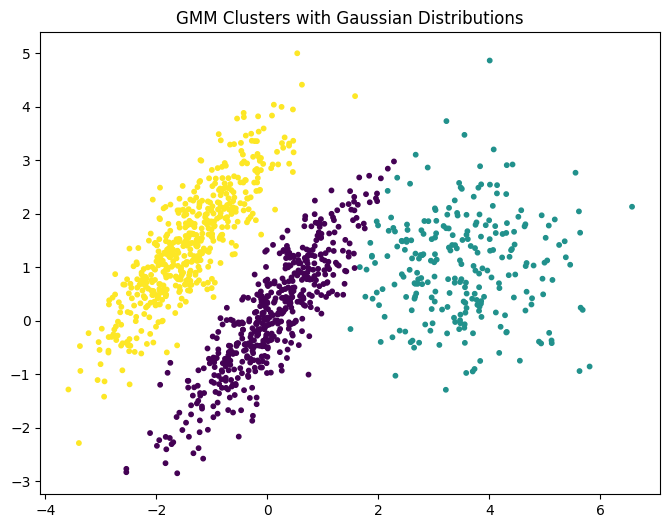

In [115]:
# Part 2: Plot data with GMM predicted clusters and Gaussian distributions
fig, ax = plt.subplots(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=10, cmap='viridis')
plt.title('GMM Clusters with Gaussian Distributions')

In [116]:
# Generate 10 new sample points from the GMM
X_new, y_new = gm.sample(10)
print("Generated new points:\n", X_new)
print("Generated new labels:\n", y_new)

Generated new points:
 [[-0.86943947 -0.32788395]
 [ 0.29817175  0.28280831]
 [-1.39462904 -1.48530879]
 [ 3.98145559  1.49986704]
 [ 3.81671773  0.53121245]
 [ 2.84138274 -0.73881373]
 [ 5.1393689   0.21993726]
 [ 4.52183348  1.18621643]
 [-0.32838009  2.10449708]
 [-2.43289349 -0.16989511]]
Generated new labels:
 [0 0 0 1 1 1 1 1 2 2]


/tmp/ipykernel_4562/925592092.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


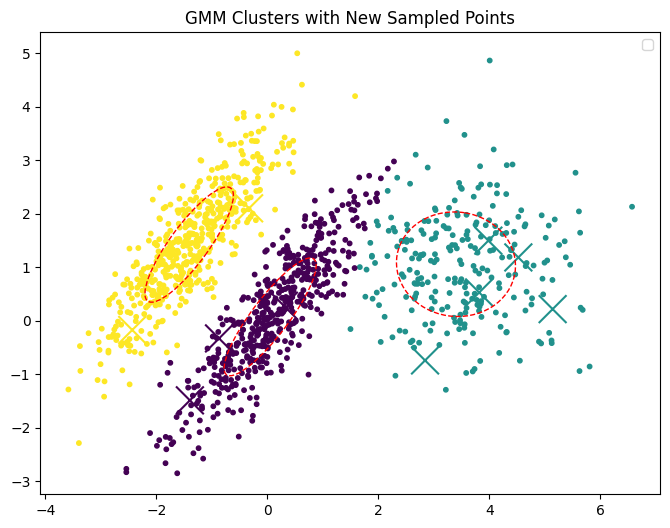

In [117]:
# Plot the new points on the same plot
fig, ax = plt.subplots(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=10, cmap='viridis')
plt.scatter(X_new[:, 0], X_new[:, 1], c=y_new, s=400, cmap='viridis', marker='x')

plt.title('GMM Clusters with New Sampled Points')
plot_gaussian_ellipses(gm, ax)
plt.legend()
plt.show()

In [118]:
gm.score_samples(X_new)

array([-3.34388534, -2.02725349, -3.51635753, -3.7032493 , -3.66169058,
       -5.30545402, -5.0916149 , -4.00814964, -3.36861308, -3.06009822])

## Experiments of Number of clusters

In [119]:
# Change number of components and compare BIC:
for k in range(1, 7):
  gm_k = GaussianMixture(n_components=k,
                         random_state=42)
  gm_k.fit(X)
  print(f"Number of components (BIC, ): {k}, BIC: {gm_k.bic(X)}")
  print(f"Number of components (AIC, ): {k}, AIC: {gm_k.aic(X)}")

Number of components (BIC, ): 1, BIC: 9330.418496222055
Number of components (AIC, ): 1, AIC: 9304.764002070573
Number of components (BIC, ): 2, BIC: 8971.197133122107
Number of components (AIC, ): 2, AIC: 8914.757245988847
Number of components (BIC, ): 3, BIC: 8189.761570083466
Number of components (AIC, ): 3, AIC: 8102.536289968428
Number of components (BIC, ): 4, BIC: 8238.656117566145
Number of components (AIC, ): 4, AIC: 8120.645444469329
Number of components (BIC, ): 5, BIC: 8273.901260465906
Number of components (AIC, ): 5, AIC: 8125.105194387312
Number of components (BIC, ): 6, BIC: 8317.689538211382
Number of components (AIC, ): 6, AIC: 8138.10807915101


In [120]:
# Different covariance types:
for cov in ['full', 'tied', 'diag', 'spherical']:
    gm_c = GaussianMixture(n_components=3, covariance_type=cov, n_init=10, random_state=42).fit(X)
    print(cov, "converged:", gm_c.converged_)

full converged: True
tied converged: True
diag converged: True
spherical converged: True


In [121]:
# Show soft probabilities:
probs = gm.predict_proba(X)
probs[:5]

array([[9.76660045e-01, 2.33392754e-02, 6.79713861e-07],
       [9.82749546e-01, 1.65734903e-02, 6.76963988e-04],
       [7.42959049e-05, 2.04887015e-06, 9.99923655e-01],
       [9.91426699e-01, 8.56462263e-03, 8.67814274e-06],
       [2.29931058e-09, 2.39103289e-08, 9.99999974e-01]])

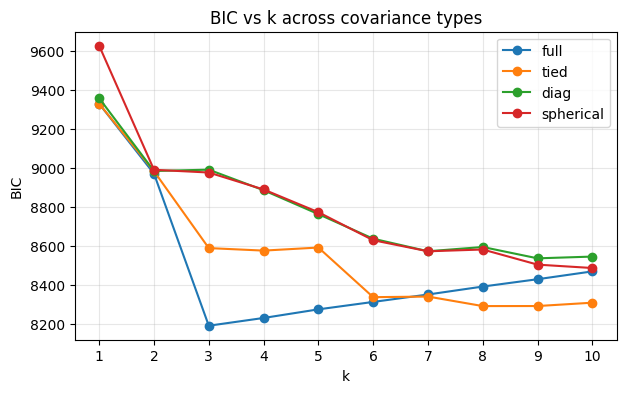

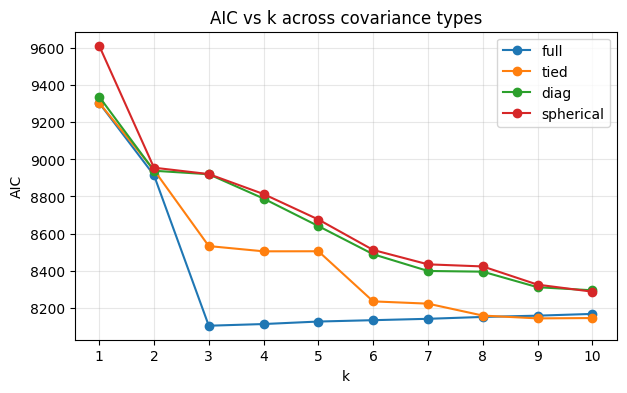

In [122]:
cov_types = ['full', 'tied', 'diag', 'spherical']
Ks = range(1, 11)
results_bic = {ct: [] for ct in cov_types}
results_aic = {ct: [] for ct in cov_types}

for ct in cov_types:
    for k in Ks:
        gm_k = GaussianMixture(n_components=k, covariance_type=ct, n_init=10, random_state=42).fit(X)
        results_bic[ct].append(gm_k.bic(X))
        results_aic[ct].append(gm_k.aic(X))

# BIC
plt.figure(figsize=(7,4))
for ct in cov_types:
    plt.plot(Ks, results_bic[ct], 'o-', label=ct)
plt.title('BIC vs k across covariance types')
plt.xlabel('k')
plt.ylabel('BIC')
plt.xticks(Ks)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# AIC
plt.figure(figsize=(7,4))
for ct in cov_types:
    plt.plot(Ks, results_aic[ct], 'o-', label=ct)
plt.title('AIC vs k across covariance types')
plt.xlabel('k')
plt.ylabel('AIC')
plt.xticks(Ks)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()
